# Imports

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [13]:
data = np.load(r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\BWR_3_1.txt_BWR_arrays.npz")


z_coordinate = data["z_temperature"]

fuel_average = data["fuel_average"]
fuel_centreline = data["fuel_centreline"]
clad_inner_surface = data["clad_inner_surface"]
clad_outer_surface = data["clad_outer_surface"]
coolant_temperature = data["coolant_temperature"]

linear_power = data["linear_power"]

void_fraction = data["void_fraction"]
z_void_fraction = data["z_void_fraction"]

# Temperature Plot Version 1

In [14]:
color_list = ["#D55E00", "#0072B2", "#009E73", "#E69F00", "#CC79A7"]
marker_list = ["o", "D", "s", "h", "v"]

labels = [
    "Fuel average",
    "Fuel centreline",
    "Clad inner surface",
    "Clad outer surface",
    "Coolant"
]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements = []

for color, marker, label in zip(color_list, marker_list, labels):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='none',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements.append(((line, marker_handle), label))

temperature_datasets = [fuel_average, fuel_centreline, clad_inner_surface, clad_outer_surface, coolant_temperature]

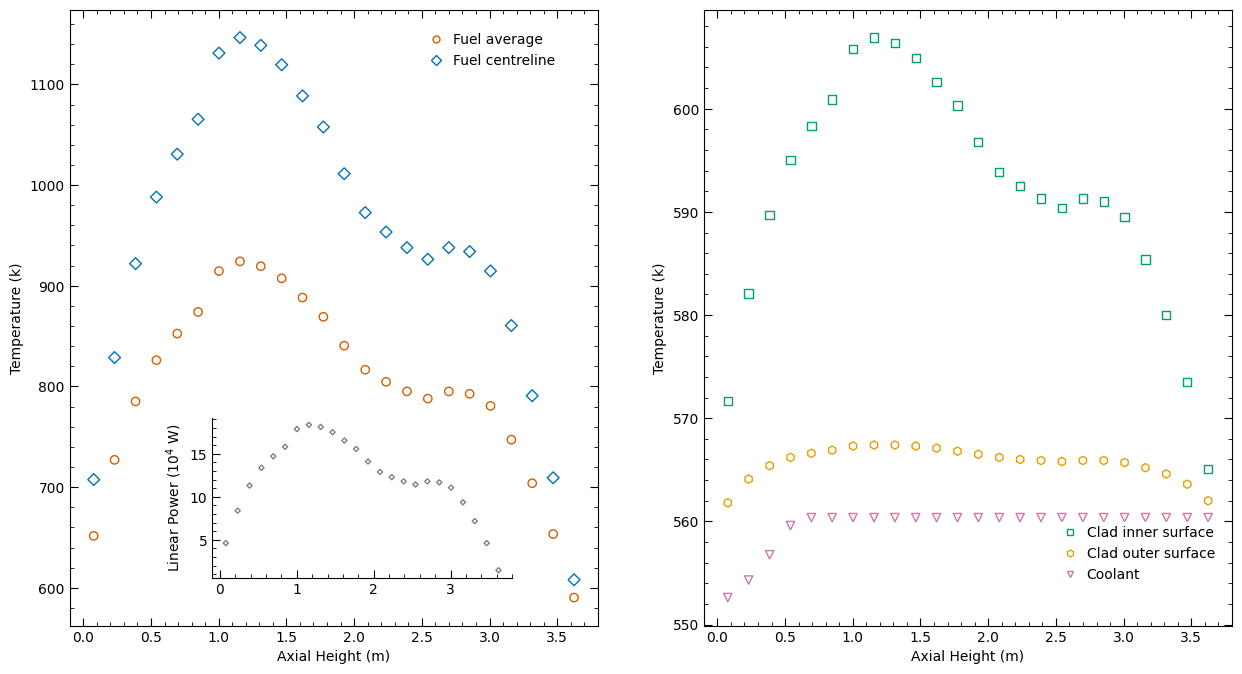

In [15]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 2
    # ,
    # height_ratios=[5, 2],
    # hspace=0
)

ax_left = fig.add_subplot(gs[0,0])
ax_right = fig.add_subplot(gs[0,1])

ax_inset = fig.add_axes([0.22,0.17,0.2,0.2]) #left, bottom, width, height


ax_left.patch.set_visible(False)
ax_right.patch.set_visible(False)

# Put inset behind the main plots
ax_inset.set_zorder(0)

ax_left.set_zorder(1)
ax_right.set_zorder(1)

split_point = 2

###########
# Left Plot
###########

for ydata, colour, marker in zip(
        temperature_datasets[0:split_point], color_list[0:split_point], marker_list[0:split_point]):
    ax_left.scatter(z_coordinate, ydata,
                    marker=marker, color=colour, facecolor="none")

ax_left.legend(
    handles=[item[0] for item in legend_elements[0:split_point]],
    labels=[item[1] for item in legend_elements[0:split_point]],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.63, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)


# inset plot

ax_inset.scatter(z_coordinate, linear_power/10e4,
                 marker = "D", color = "grey", s =7, facecolor="none")

ax_inset.set_ylabel("Linear Power ($10^{4}$ W)")



############
# Right Plot
############

for ydata, colour, marker in zip(
        temperature_datasets[split_point:], color_list[split_point:], marker_list[split_point:]):
    ax_right.scatter(z_coordinate, ydata,
                    marker=marker, color=colour, facecolor="none")

ax_right.legend(
    handles=[item[0] for item in legend_elements[split_point:]],
    labels=[item[1] for item in legend_elements[split_point:]],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.63, 0.18),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

# ###############
# # Residual Plot
# ###############
#
#
# for residual, colour, marker in zip(
#         residuals, color_list, marker_list):
#     ax_res.scatter(z_coordinates, residual,
#                    marker=marker, color=colour, facecolor="none")
#
# ax_res.axhline(0, linestyle="--", color="black", alpha=0.5)
# ax_res.axhline(1, linestyle="--", color="grey", alpha=0.5)
# ax_res.axhline(-1, linestyle="--", color="grey", alpha=0.5)
#
# ax_res.set_ylabel("Residual")

#####################
# Formatting and Save
#####################

ax_left.set_xlabel("Axial Height (m)")
ax_left.set_ylabel("Temperature (k)")

ax_right.set_xlabel("Axial Height (m)")
ax_right.set_ylabel("Temperature (k)")

for ax in [ax_left, ax_right]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

ax_inset.minorticks_on()
ax_inset.tick_params(which='major', size=6, direction='in',
                   right=False, top=False)
ax_inset.tick_params(which='minor', size=3, direction='in',
                   right=False, top=False)
ax_inset.spines['top'].set_visible(False)
ax_inset.spines['right'].set_visible(False)

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\BWR_3_1_Temperature_Plot_v1.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Temperature Plot Version 2

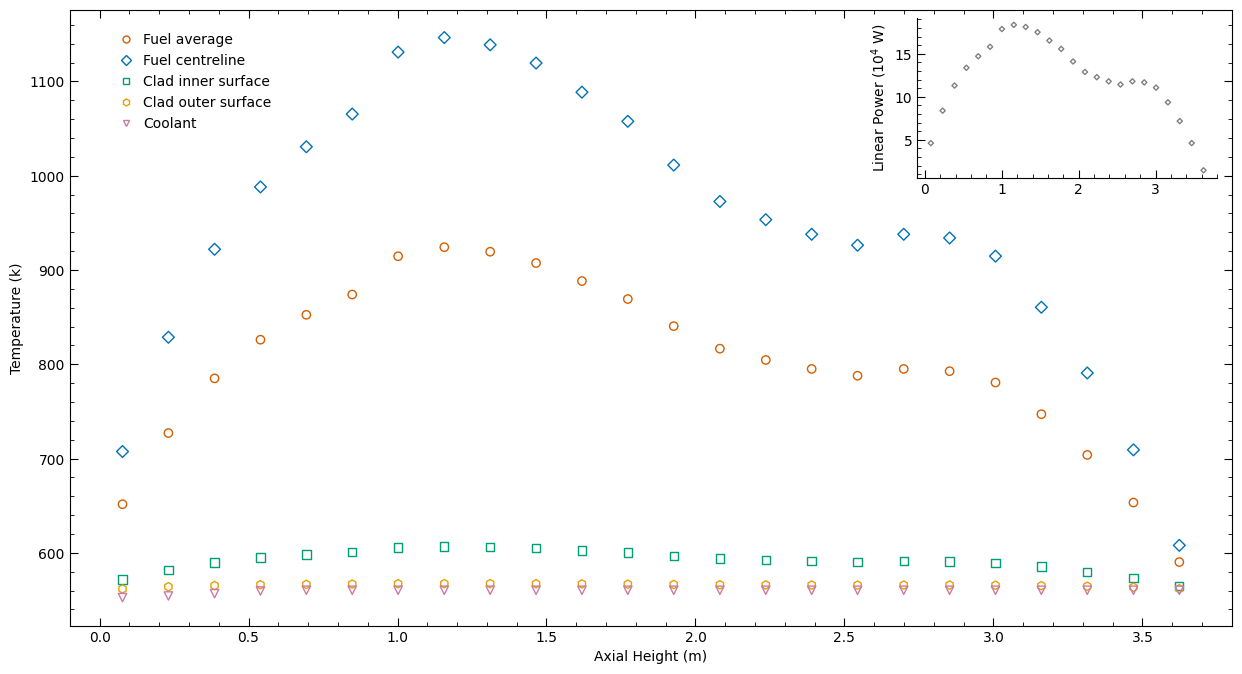

In [16]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1
    # ,
    # height_ratios=[5, 2],
    # hspace=0
)

ax_main = fig.add_subplot(gs[0])


ax_inset = fig.add_axes([0.69,0.67,0.2,0.2]) #left, bottom, width, height


ax_main.patch.set_visible(False)

# Put inset behind the main plot
ax_inset.set_zorder(0)
ax_main.set_zorder(1)

###########
# Main Plot
###########

for ydata, colour, marker in zip(
        temperature_datasets, color_list, marker_list):
    ax_main.scatter(z_coordinate, ydata,
                    marker=marker, color=colour, facecolor="none")

ax_main.legend(
    handles=[item[0] for item in legend_elements],
    labels=[item[1] for item in legend_elements],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)


# inset plot

ax_inset.scatter(z_coordinate, linear_power/10e4,
                 marker = "D", color = "grey", s =7, facecolor="none")

ax_inset.set_ylabel("Linear Power ($10^{4}$ W)")

#####################
# Formatting and Save
#####################

ax_main.set_xlabel("Axial Height (m)")
ax_main.set_ylabel("Temperature (k)")

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

ax_inset.minorticks_on()
ax_inset.tick_params(which='major', size=6, direction='in',
                   right=False, top=False)
ax_inset.tick_params(which='minor', size=3, direction='in',
                   right=False, top=False)
ax_inset.spines['top'].set_visible(False)
ax_inset.spines['right'].set_visible(False)

plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\BWR_3_1_Temperature_Plot_v2.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Temperature Plot Version 3

In [17]:
color_list_V3 = ["#D55E00", "#0072B2", "#009E73", "#E69F00", "#CC79A7", "red"]
marker_list_V3 = ["o", "D", "s", "h", "v", "8"]

labels_V3 = [
    "Fuel average",
    "Fuel centreline",
    "Clad inner surface",
    "Clad outer surface",
    "Coolant",
    "Linear Power"
]

from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
from matplotlib.legend_handler import HandlerTuple

legend_elements_V3 = []

for color, marker, label in zip(color_list_V3, marker_list_V3, labels_V3):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle='none',
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_V3.append(((line, marker_handle), label))

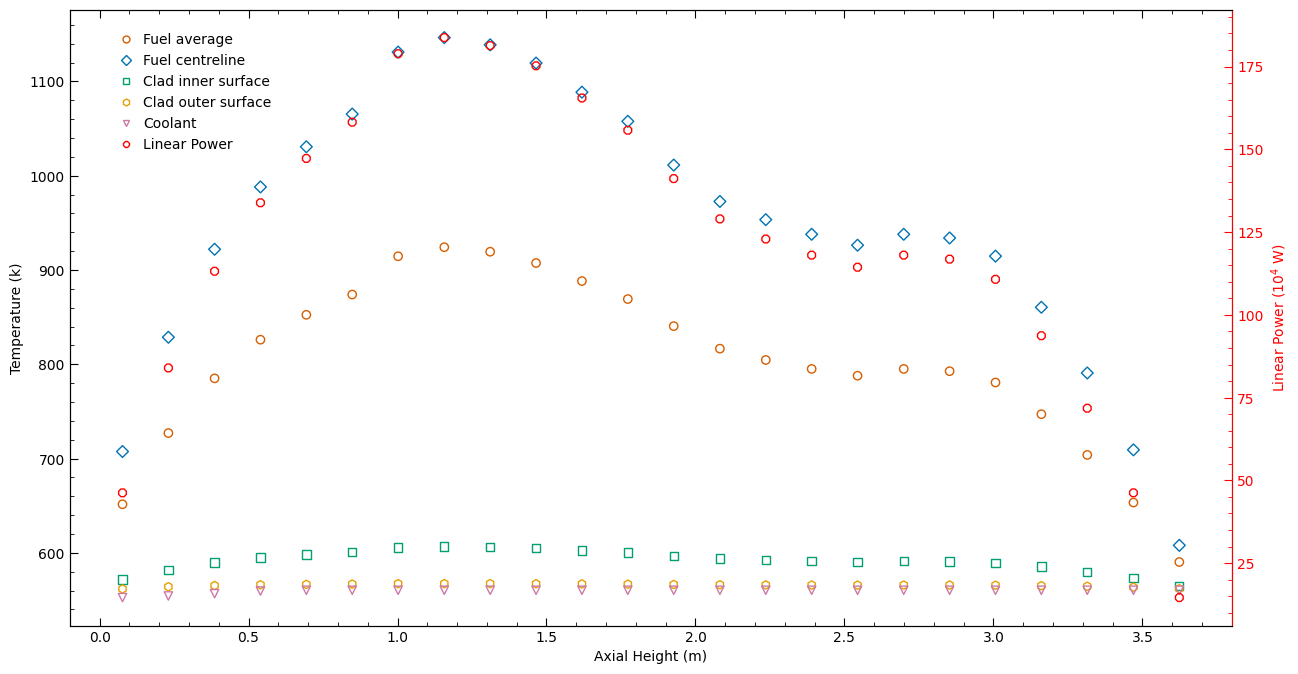

In [18]:
#######
# Setup
#######

fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1
)

ax_main = fig.add_subplot(gs[0])
ax_power = ax_main.twinx()

###########
# Main Plot
###########

for ydata, colour, marker in zip(
        temperature_datasets, color_list_V3[:-1], marker_list_V3[:-1]):
    ax_main.scatter(z_coordinate, ydata,
                    marker=marker, color=colour, facecolor="none")





ax_power.scatter(z_coordinate, linear_power / 1e4,
                 marker= marker_list_V3[-1], color= color_list_V3[-1], facecolor="none")

# Colour right-hand axis red
ax_power.set_ylabel("Linear Power ($10^{4}$ W)", color="red")

ax_power.tick_params(
    axis='y',
    which='both',
    colors='red'
)

ax_power.spines['right'].set_color('red')


ax_main.legend(
    handles=[item[0] for item in legend_elements_V3],
    labels=[item[1] for item in legend_elements_V3],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.02, 0.98),
    borderpad=0.3,
    facecolor="white",
    edgecolor="white",
    framealpha=1
)

#####################
# Formatting and Save
#####################

ax_main.set_xlabel("Axial Height (m)")
ax_main.set_ylabel("Temperature (k)")

for ax in [ax_main, ax_power]:
    ax.minorticks_on()

    ax.tick_params(
        which='major',
        size=6,
        direction='in',
        top=True
    )

    ax.tick_params(
        which='minor',
        size=3,
        direction='in',
        top=True
    )
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))

# Main axis: show ticks on left and bottom
ax_main.tick_params(axis='y', left=True, right=False)

# Secondary axis: show ticks on right
ax_power.tick_params(axis='y', left=False, right=True)

# Ensure the secondary axis has no visible background
ax_power.patch.set_visible(False)


plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\BWR_3_1_Temperature_Plot_v3.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Void Fraction Plot

In [19]:
primary_color = "grey"
primary_marker = "D"

labels_VF = [
    "Void fraction"
]

legend_elements_VF = []

for color, marker, label in zip([primary_color], [primary_marker], labels_VF):
    line = Line2D(
        [0], [0],
        color=to_rgba(color, 0.3),
        linestyle="none",
        linewidth=1.5
    )

    marker_handle = Line2D(
        [0], [0],
        color=color,
        marker=marker,
        linestyle='None',
        markerfacecolor='none',
        markeredgecolor=color,
        markersize=5
    )

    legend_elements_VF.append(((line, marker_handle), label))

idx = np.flatnonzero(void_fraction)[0]
z_boiling = z_void_fraction[idx]

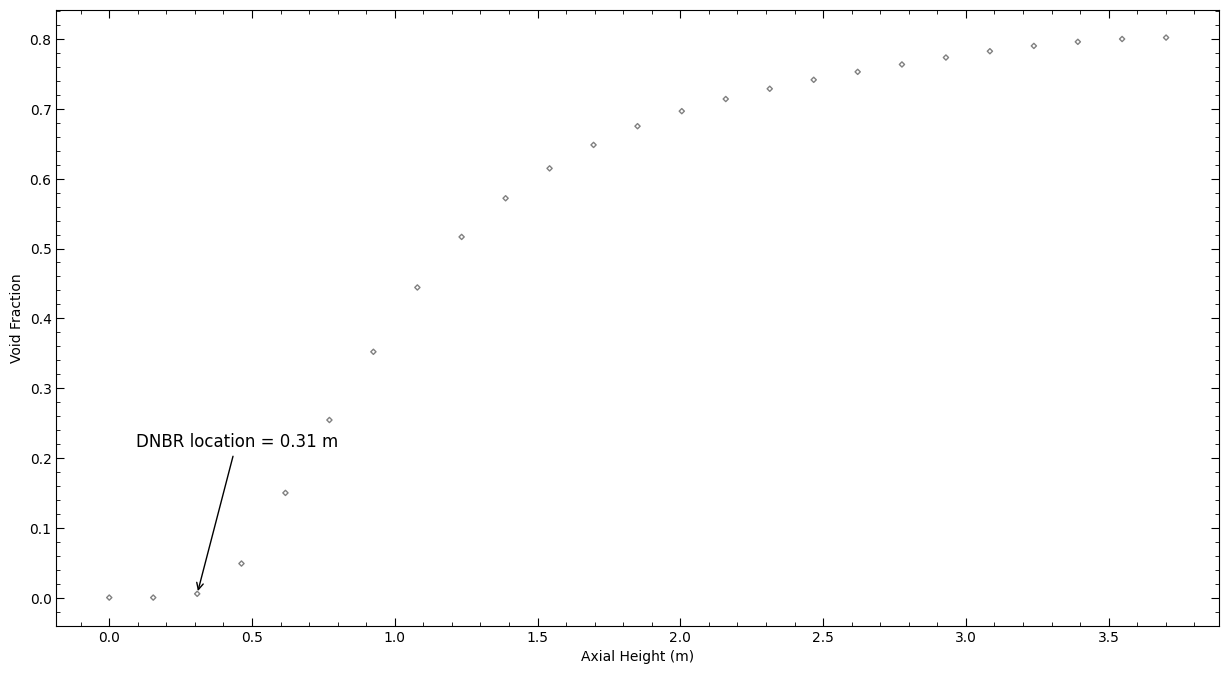

In [23]:
fig = plt.figure(figsize=(15, 8))

gs = fig.add_gridspec(
    1, 1
)

ax_main = fig.add_subplot(gs[0,0])

ax_main.scatter(z_void_fraction, void_fraction,
                color = primary_color, marker = primary_marker, s = 7, facecolor="none")


ax_main.set_ylabel("Void Fraction")
ax_main.set_xlabel("Axial Height (m)")

ax_main.annotate(
    rf"DNBR location = {z_boiling:.2f} m",
    xy=(z_void_fraction[idx], void_fraction[idx]),
    xytext=(z_void_fraction[idx]*0.3, void_fraction[idx]*40),
    arrowprops=dict(arrowstyle="->", color="black", lw=1),
    color="black",
    fontsize=12
)


#####################
# Formatting and Save
#####################

for ax in [ax_main]:
    ax.minorticks_on()
    ax.tick_params(which='major', size=6, direction='in',
                   right=True, top=True)
    ax.tick_params(which='minor', size=3, direction='in',
                   right=True, top=True)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_bbox(dict(
            facecolor="white",
            edgecolor="none",
            pad=1.0
        ))


plt.savefig(
    r"C:\Users\sebas\Documents\Cambridge\NE2 Reactor Engineering\COBRA Project\Plots\BWR_3_1_Void_Fraction_Plot.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()